In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pylabdd as dd
from matplotlib.gridspec import GridSpec
print(f'pyLabDD version {dd.__version__}')


pyLabDD version 1.3.1


In [2]:
# Read data from file if avaiable
#gbdd = dd.GB_dislocations(from_file="../data/pu1_T5000_H050_L10.h5")
gbdd = dd.GB_dislocations(from_file="../data/pu1_T900_H050_L10.h5")

In [ ]:
# Run simulation if necessary
# set simulation parameters
temp = 900.0
tau0 = 1.e-4
lgb = 1.
gs = .5
delta = 0.004
ngbn = int(lgb/delta)
if ngbn % 2 == 0: ngbn += 1
dtmax = 6.25e-7/delta**4  # value 1.e4 for delta=0.005, 50. for PU
#grain_size = 1.0
tfin = 3.e8
niter = 15_000_000
drag = 500.  # 1.e6

# run special simulation with 1 immobile dislocation in pile up with drag > 1.e5
print(f"Simulation with N_gbn={ngbn}, grain_size={gs}, dtmax={dtmax}")
gbdd = dd.GB_dislocations(temp=temp, tau0=tau0,
                   Ngbn=ngbn, len_gb_seg=lgb, grain_size=gs,
                   tfin=tfin, niter=niter,
                   dtmax=dtmax, drag=drag, fcrit=1.e9, 
                   Qact=95.0e3,
                   screenout=True)
pud = np.ones(1)*0.5*gs
gbdd.run_sim(pudis=pud)
gbdd.save_hdf5(f"pu1_T{int(temp)}_H0{int(gs*100)}_L{int(lgb*10)}.h5")
gbdd.plot_time_series(['n_gbdis_eff']) # , file="ngb_T5000_L1_d025_stat.pdf")
gbdd.plot_field('bfield', fs=26, lw=3, nplot=5) # , file="gbr_T5000_L1_d025_stat.pdf")
#gbdd.plot_time_series(['timestep', 'n_gbdis_eff'])
#gbdd.plot_time_series('plastic_slip', fs=26, lw=3)
#gbdd.plot_field('displacement', fs=26, lw=4, nplot=5,
##                file=f"tau{int(tau0)}_T{int(temp)}_D{int(gs*10)}.pdf"
#               )
#gbdd.plot_field('bfield', fs=26, lw=3, nplot=5,
##                file=f"tau{int(tau0)}_T{int(temp)}_D{int(gs*10)}.pdf"
#               )



In [ ]:
#plt.plot(gbdd.sim_time[:180], gbdd.pu_dis['force'][:180], 'b-')
plt.plot(gbdd.pu_dis['position'][:], gbdd.pu_dis['force'][:], 'b-')
plt.xlabel(r'position ($\mu$m)')
plt.ylabel('force (N/m)')
#plt.savefig("F_y_T5000_L1_d25_dyn4.pdf", dpi=300)
plt.show()

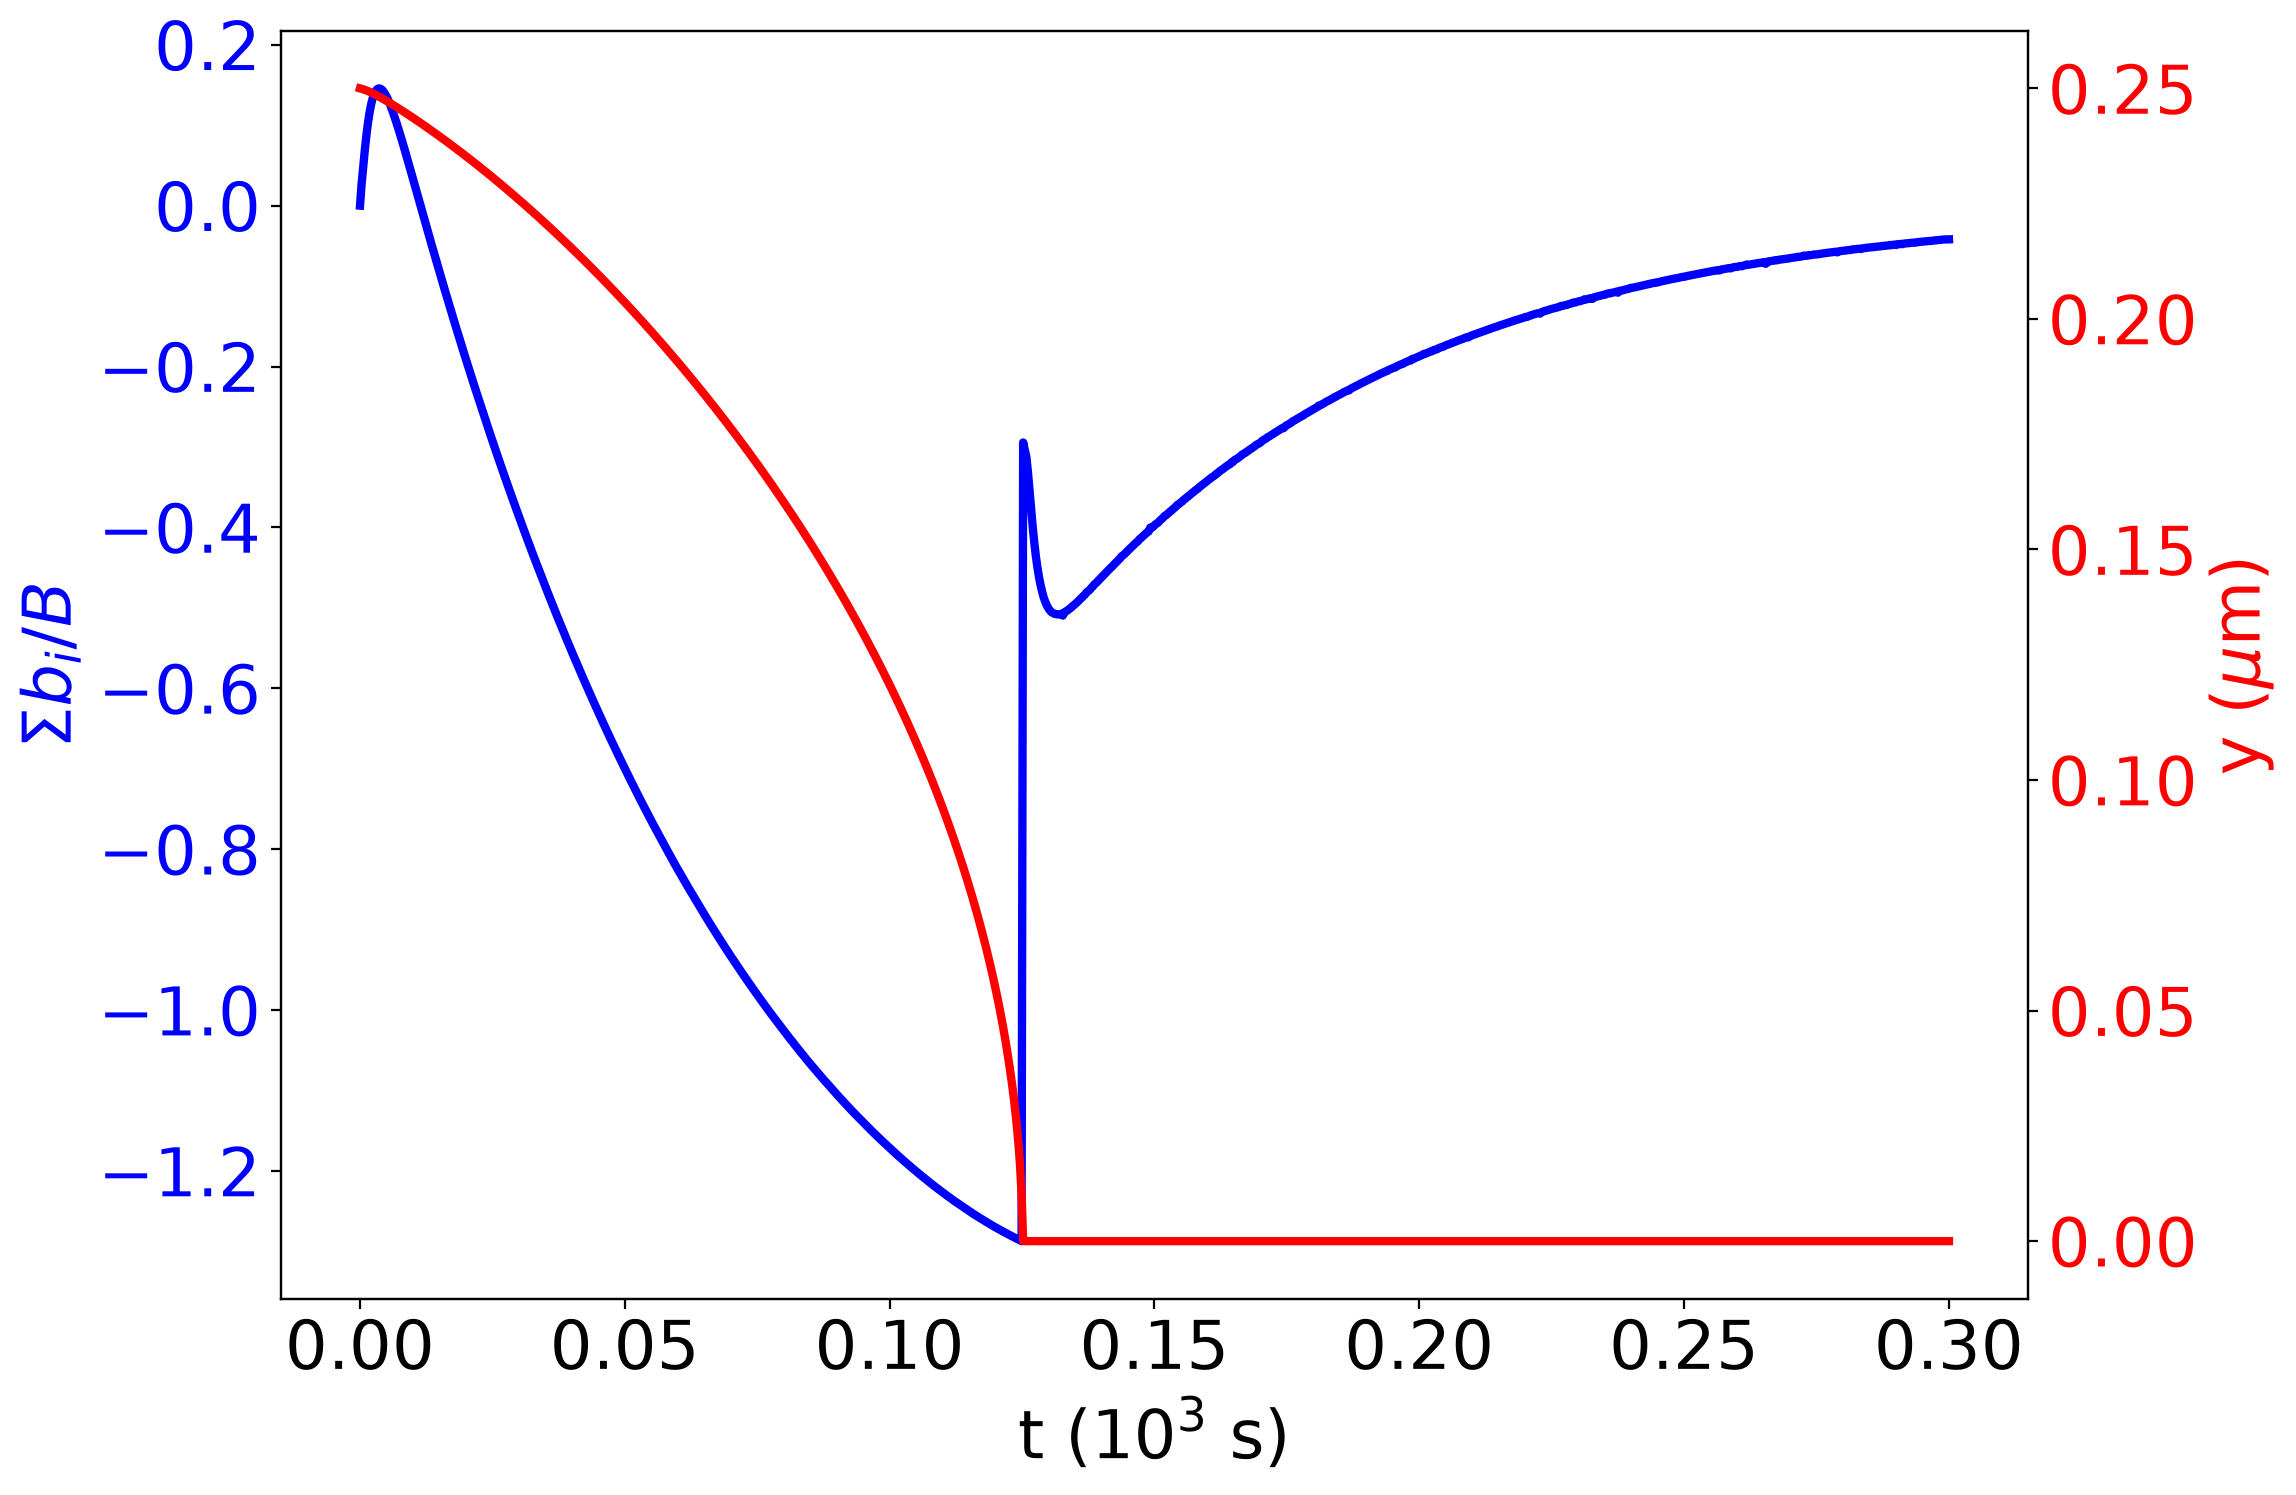

In [3]:
plt.rcParams["font.size"] = 24
fig, ax1 = plt.subplots(figsize=(12, 8), dpi=200)

# plot total B on the left axis
ax1.set_xlabel(r't (10$^3$ s)')
ax1.set_ylabel(r'$\Sigma b_i/B$', color="b")
ax1.plot(gbdd.sim_time[:]*1.e-9, gbdd.glob_data['n_gbdis_eff'][:], 
         'b-', lw=3)
ax1.tick_params(axis="y", labelcolor="b")

# Create a second axes sharing the same x-axis
ax2 = ax1.twinx()

# Second plot on the right axis
ax2.set_ylabel(r"y ($\mu$m)", color="r")
ax2.plot(gbdd.sim_time[:]*1.e-9, gbdd.pu_dis['position'][:], 
         'r-', lw=3)
ax2.tick_params(axis="y", labelcolor="r")

# Adjust layout to prevent label clipping
fig.tight_layout()
plt.savefig("pu1-relax-totalB_y.pdf", dpi=300)
plt.show()

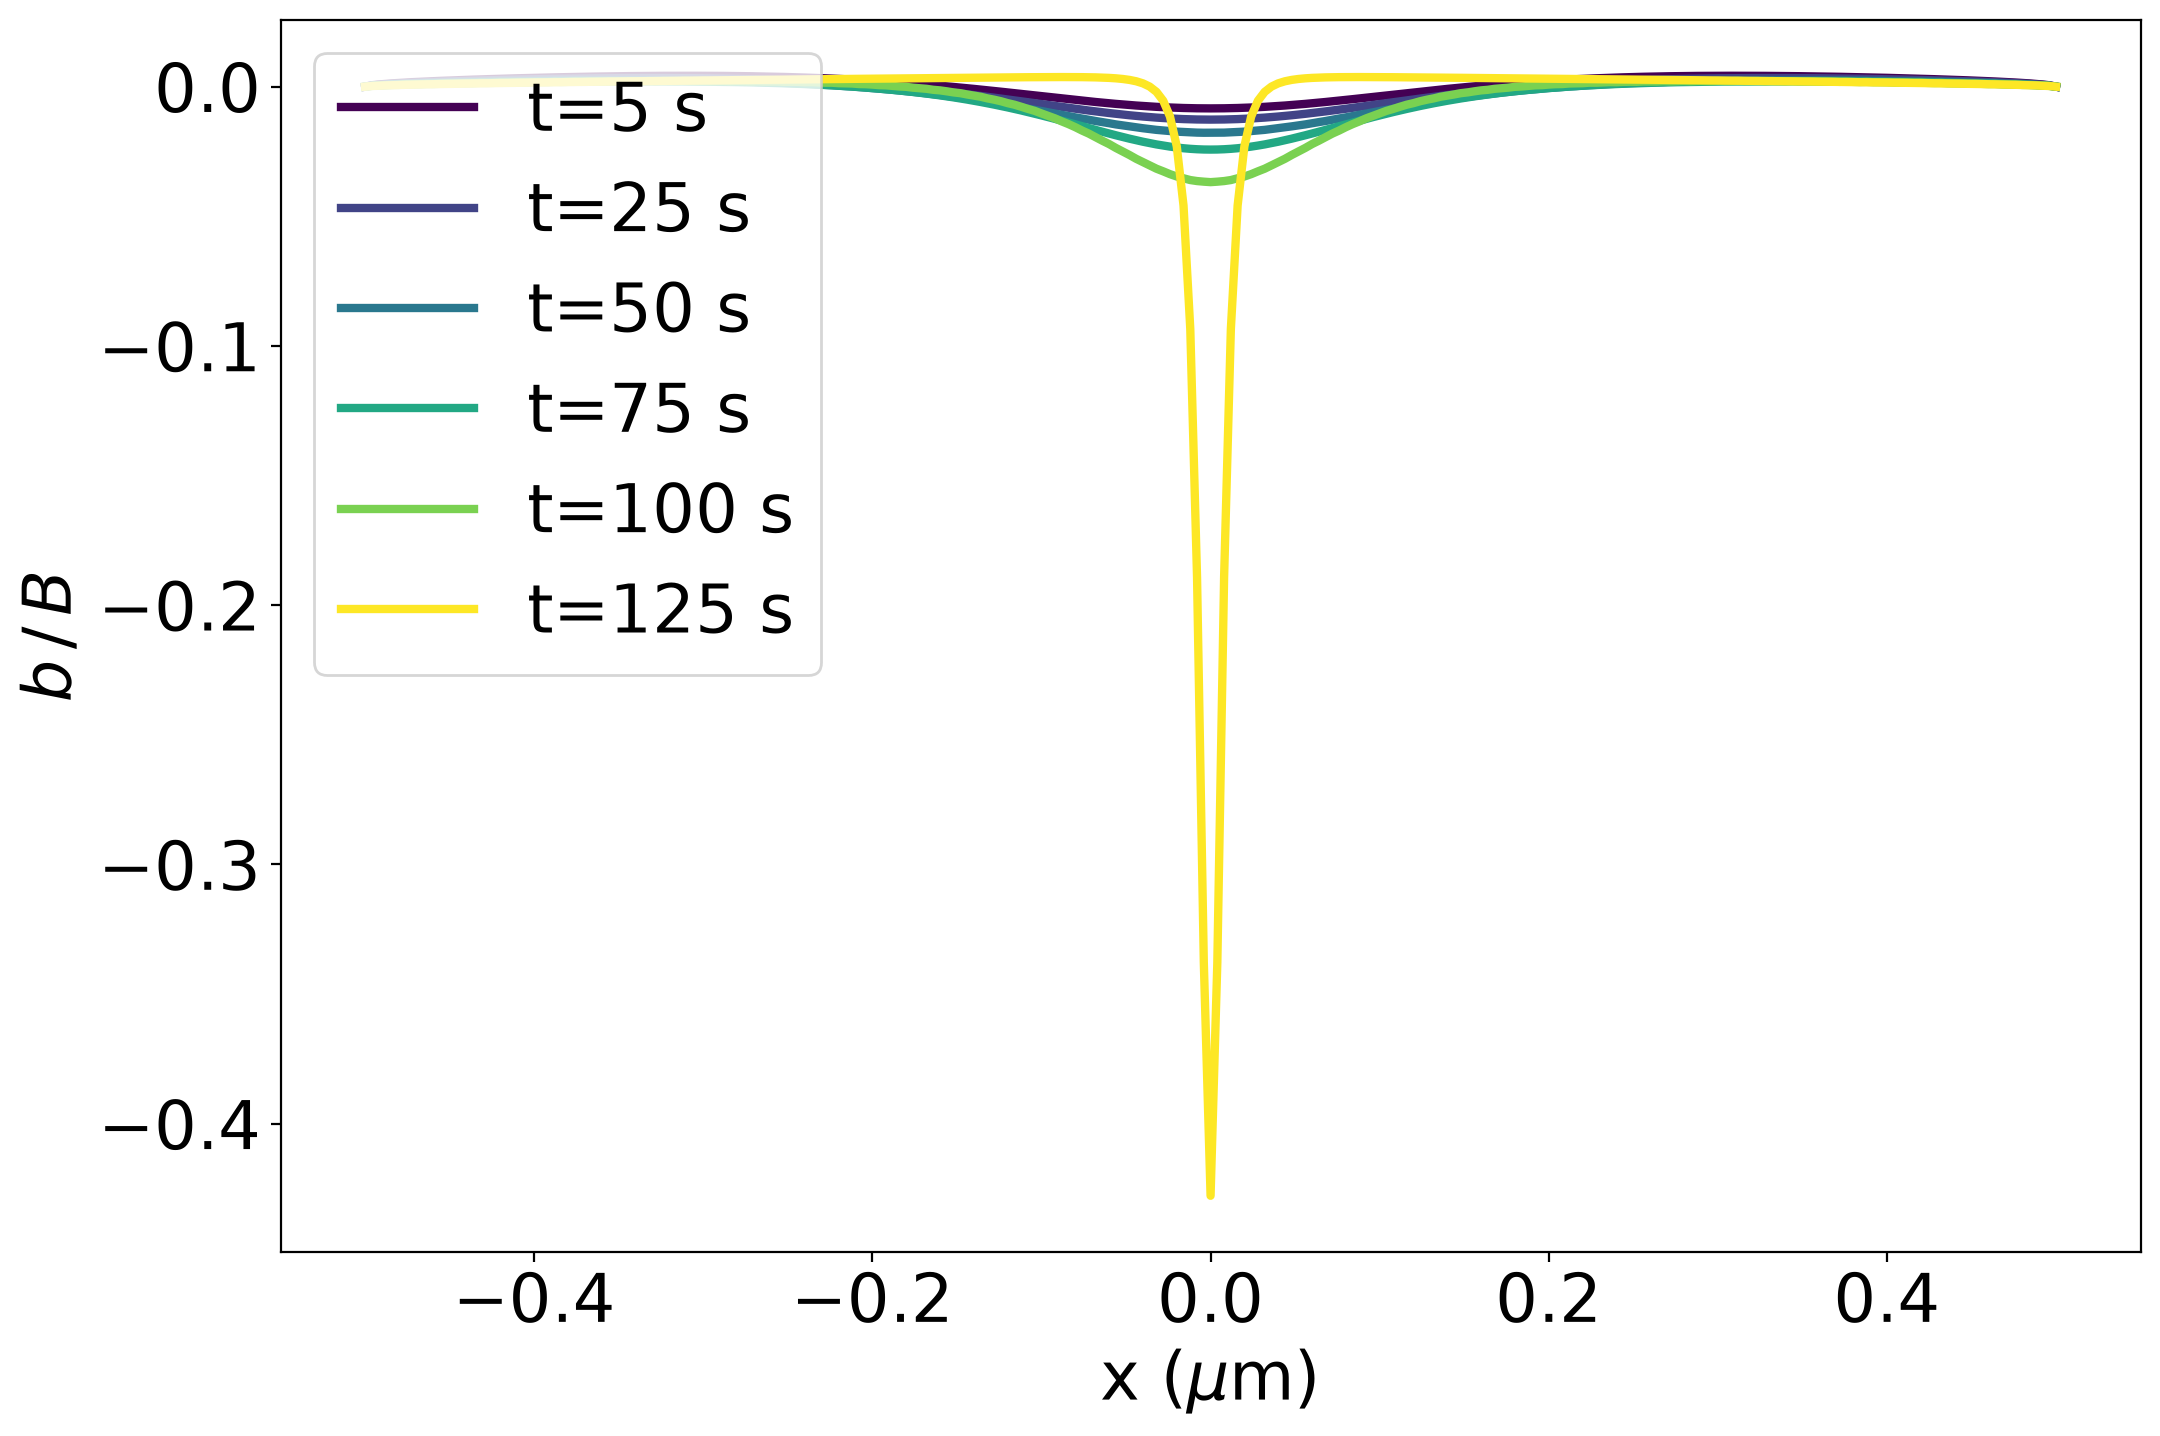

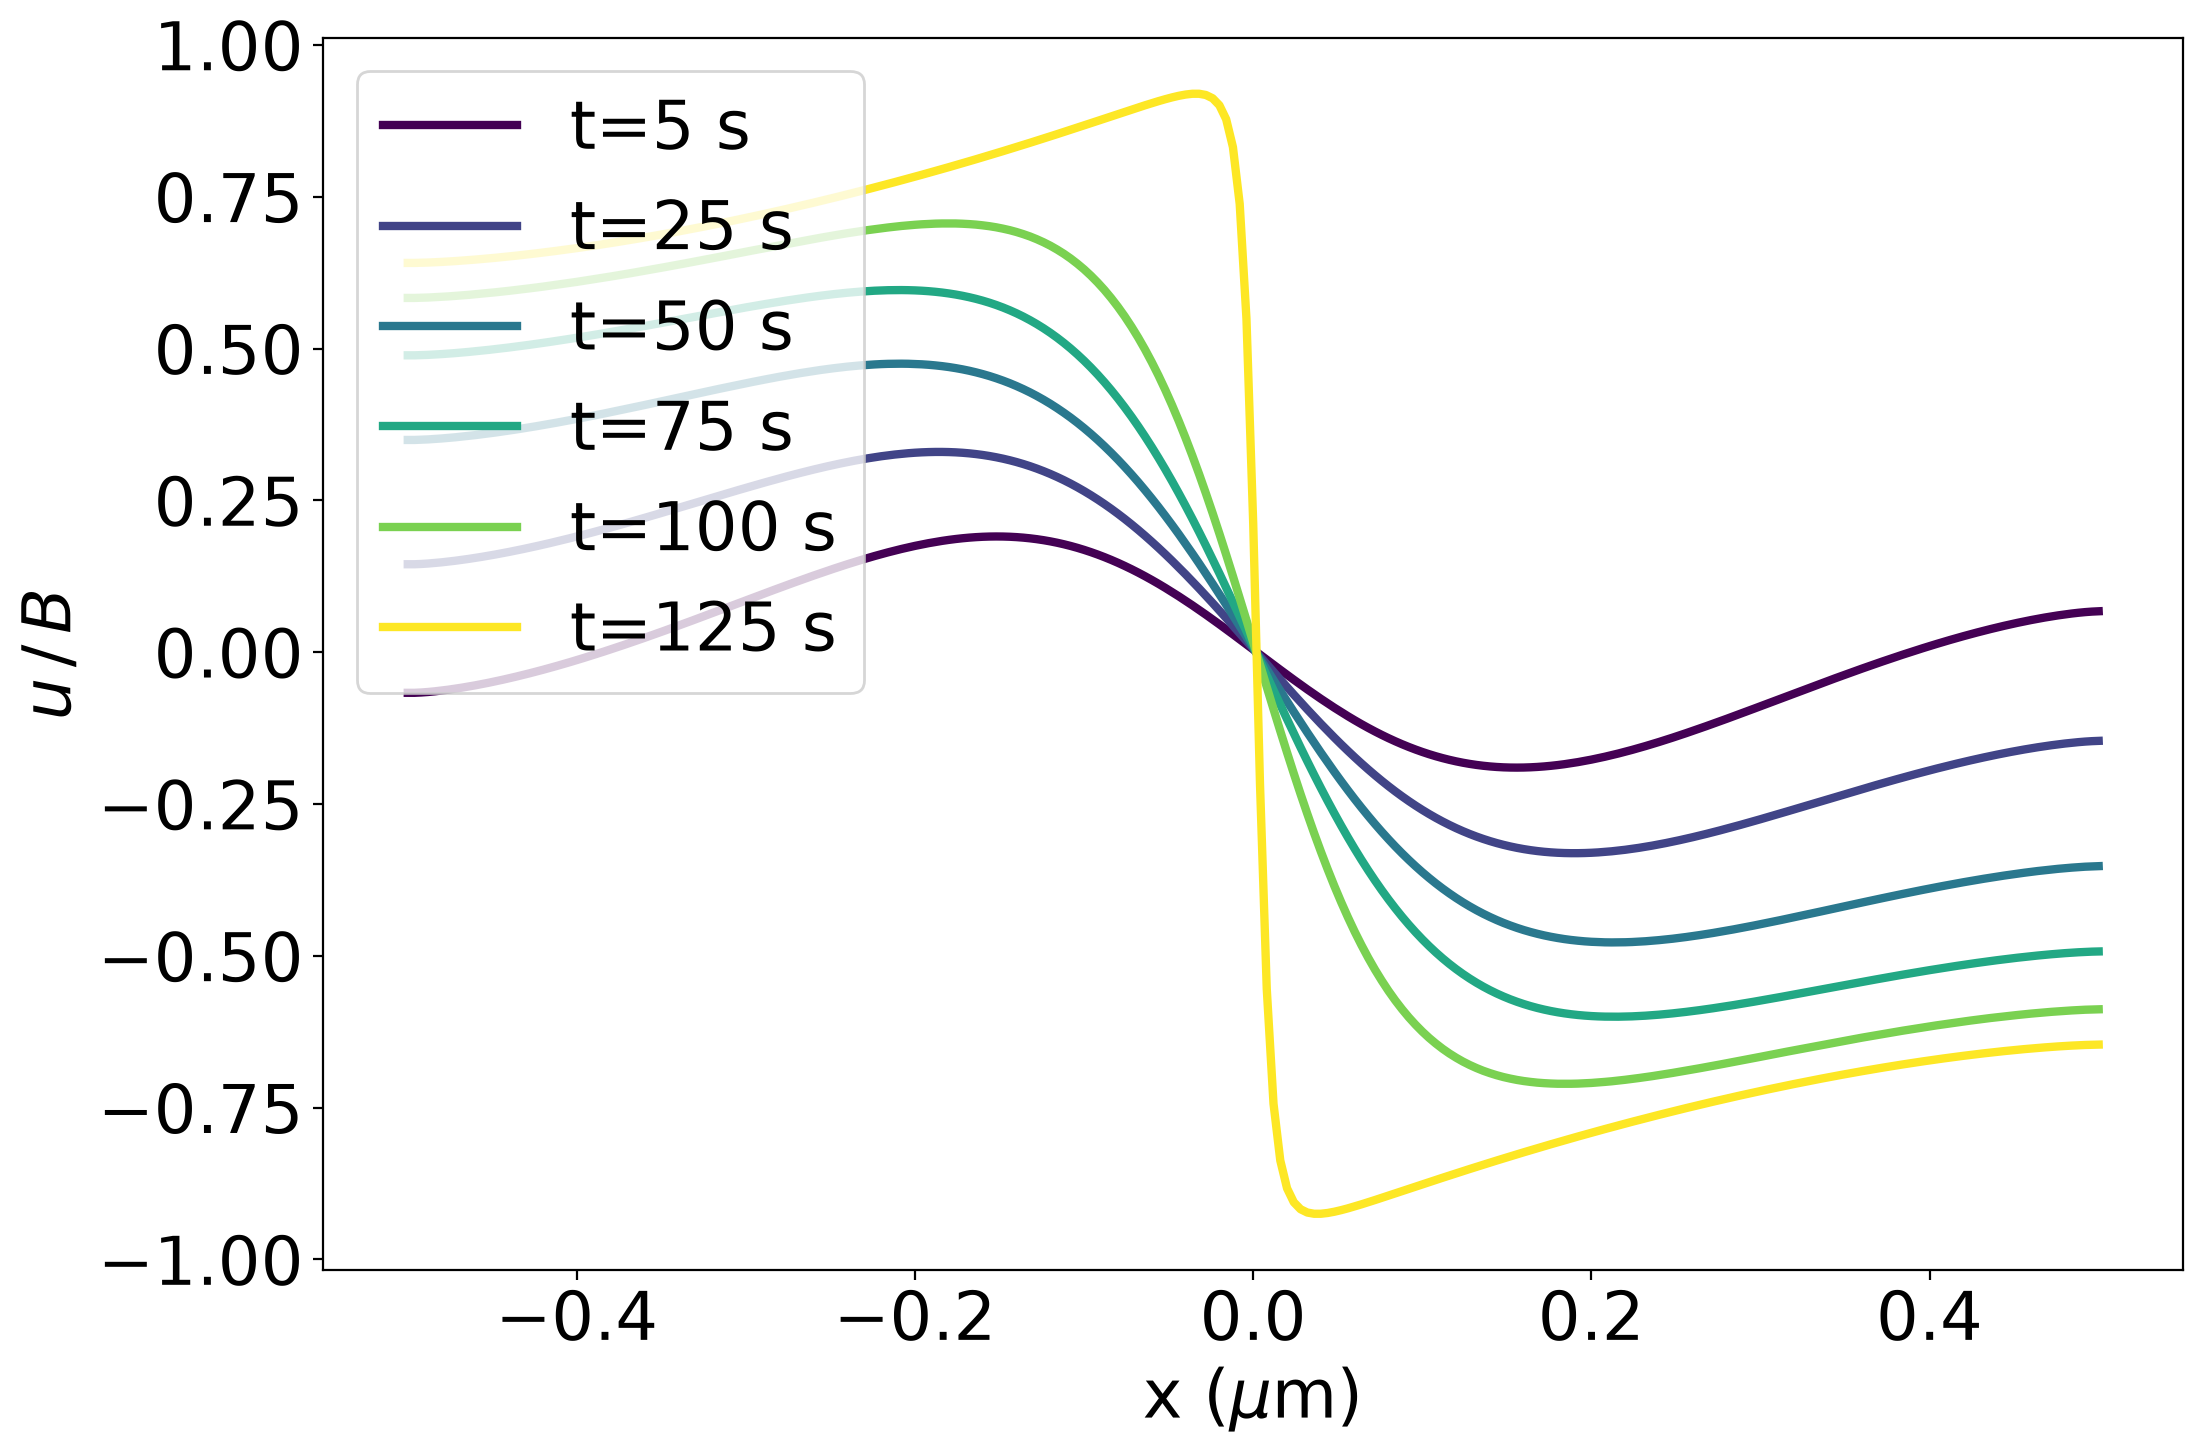

In [4]:
gbdd.plot_field("bfield", times=[5, 25, 50, 75, 100, 125],
                lw=3,
                file="pu1_relax_bfield_before.pdf")
gbdd.plot_field("displacement", times=[5, 25, 50, 75, 100, 125],
                lw=3,
               file="pu1_relax_disp_before.pdf")

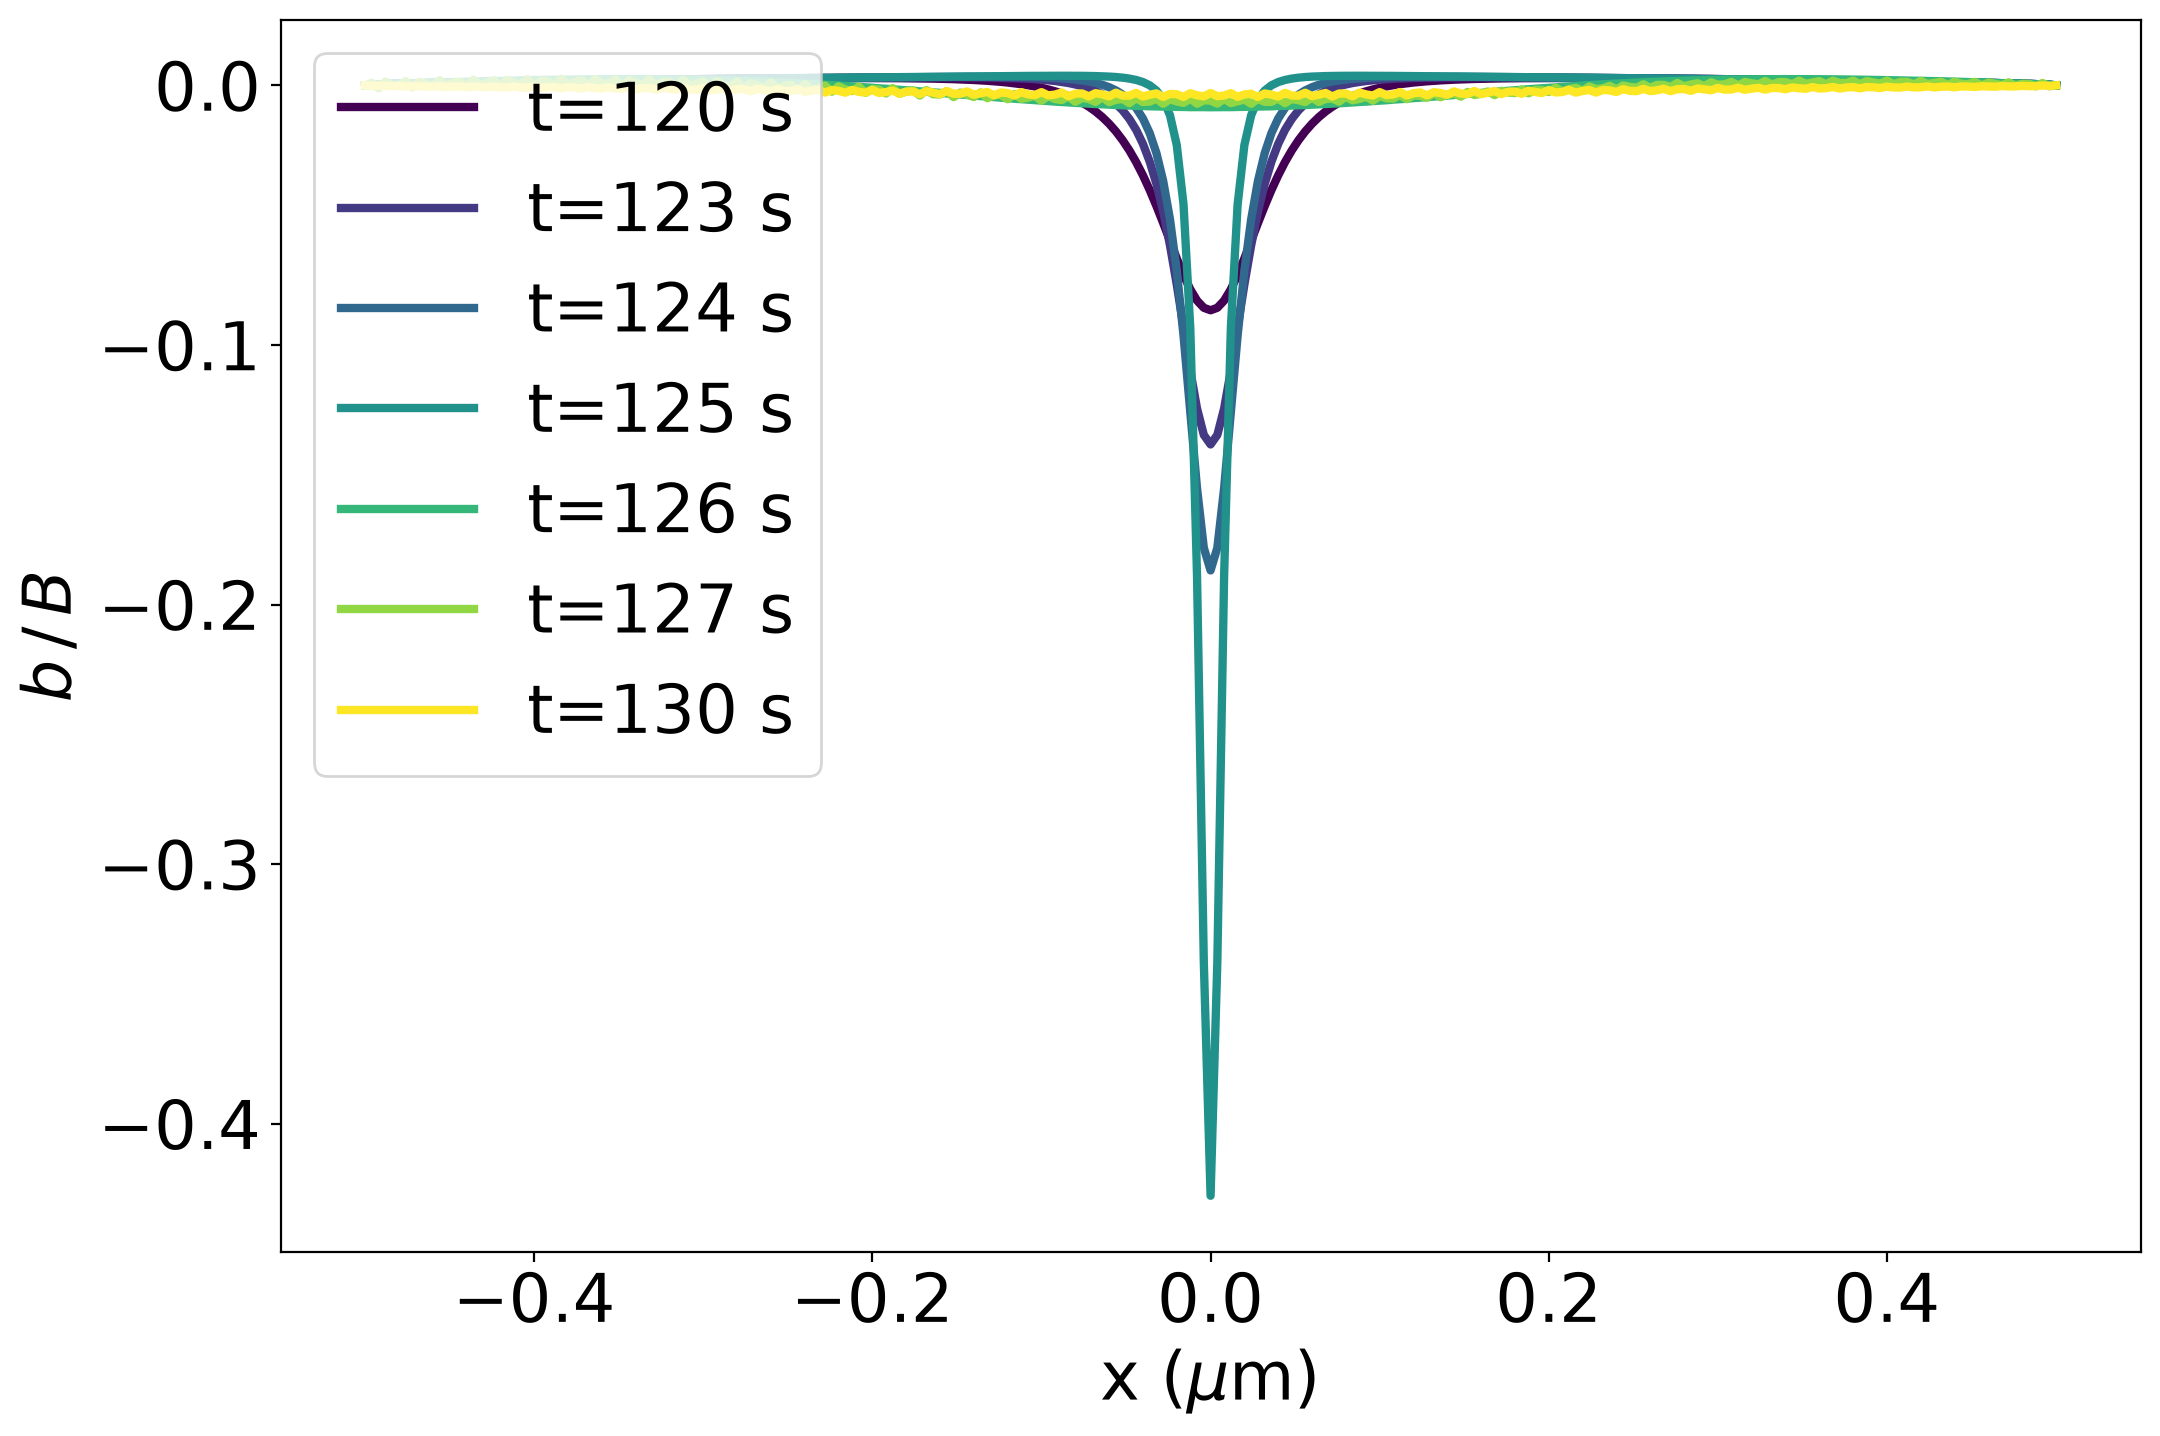

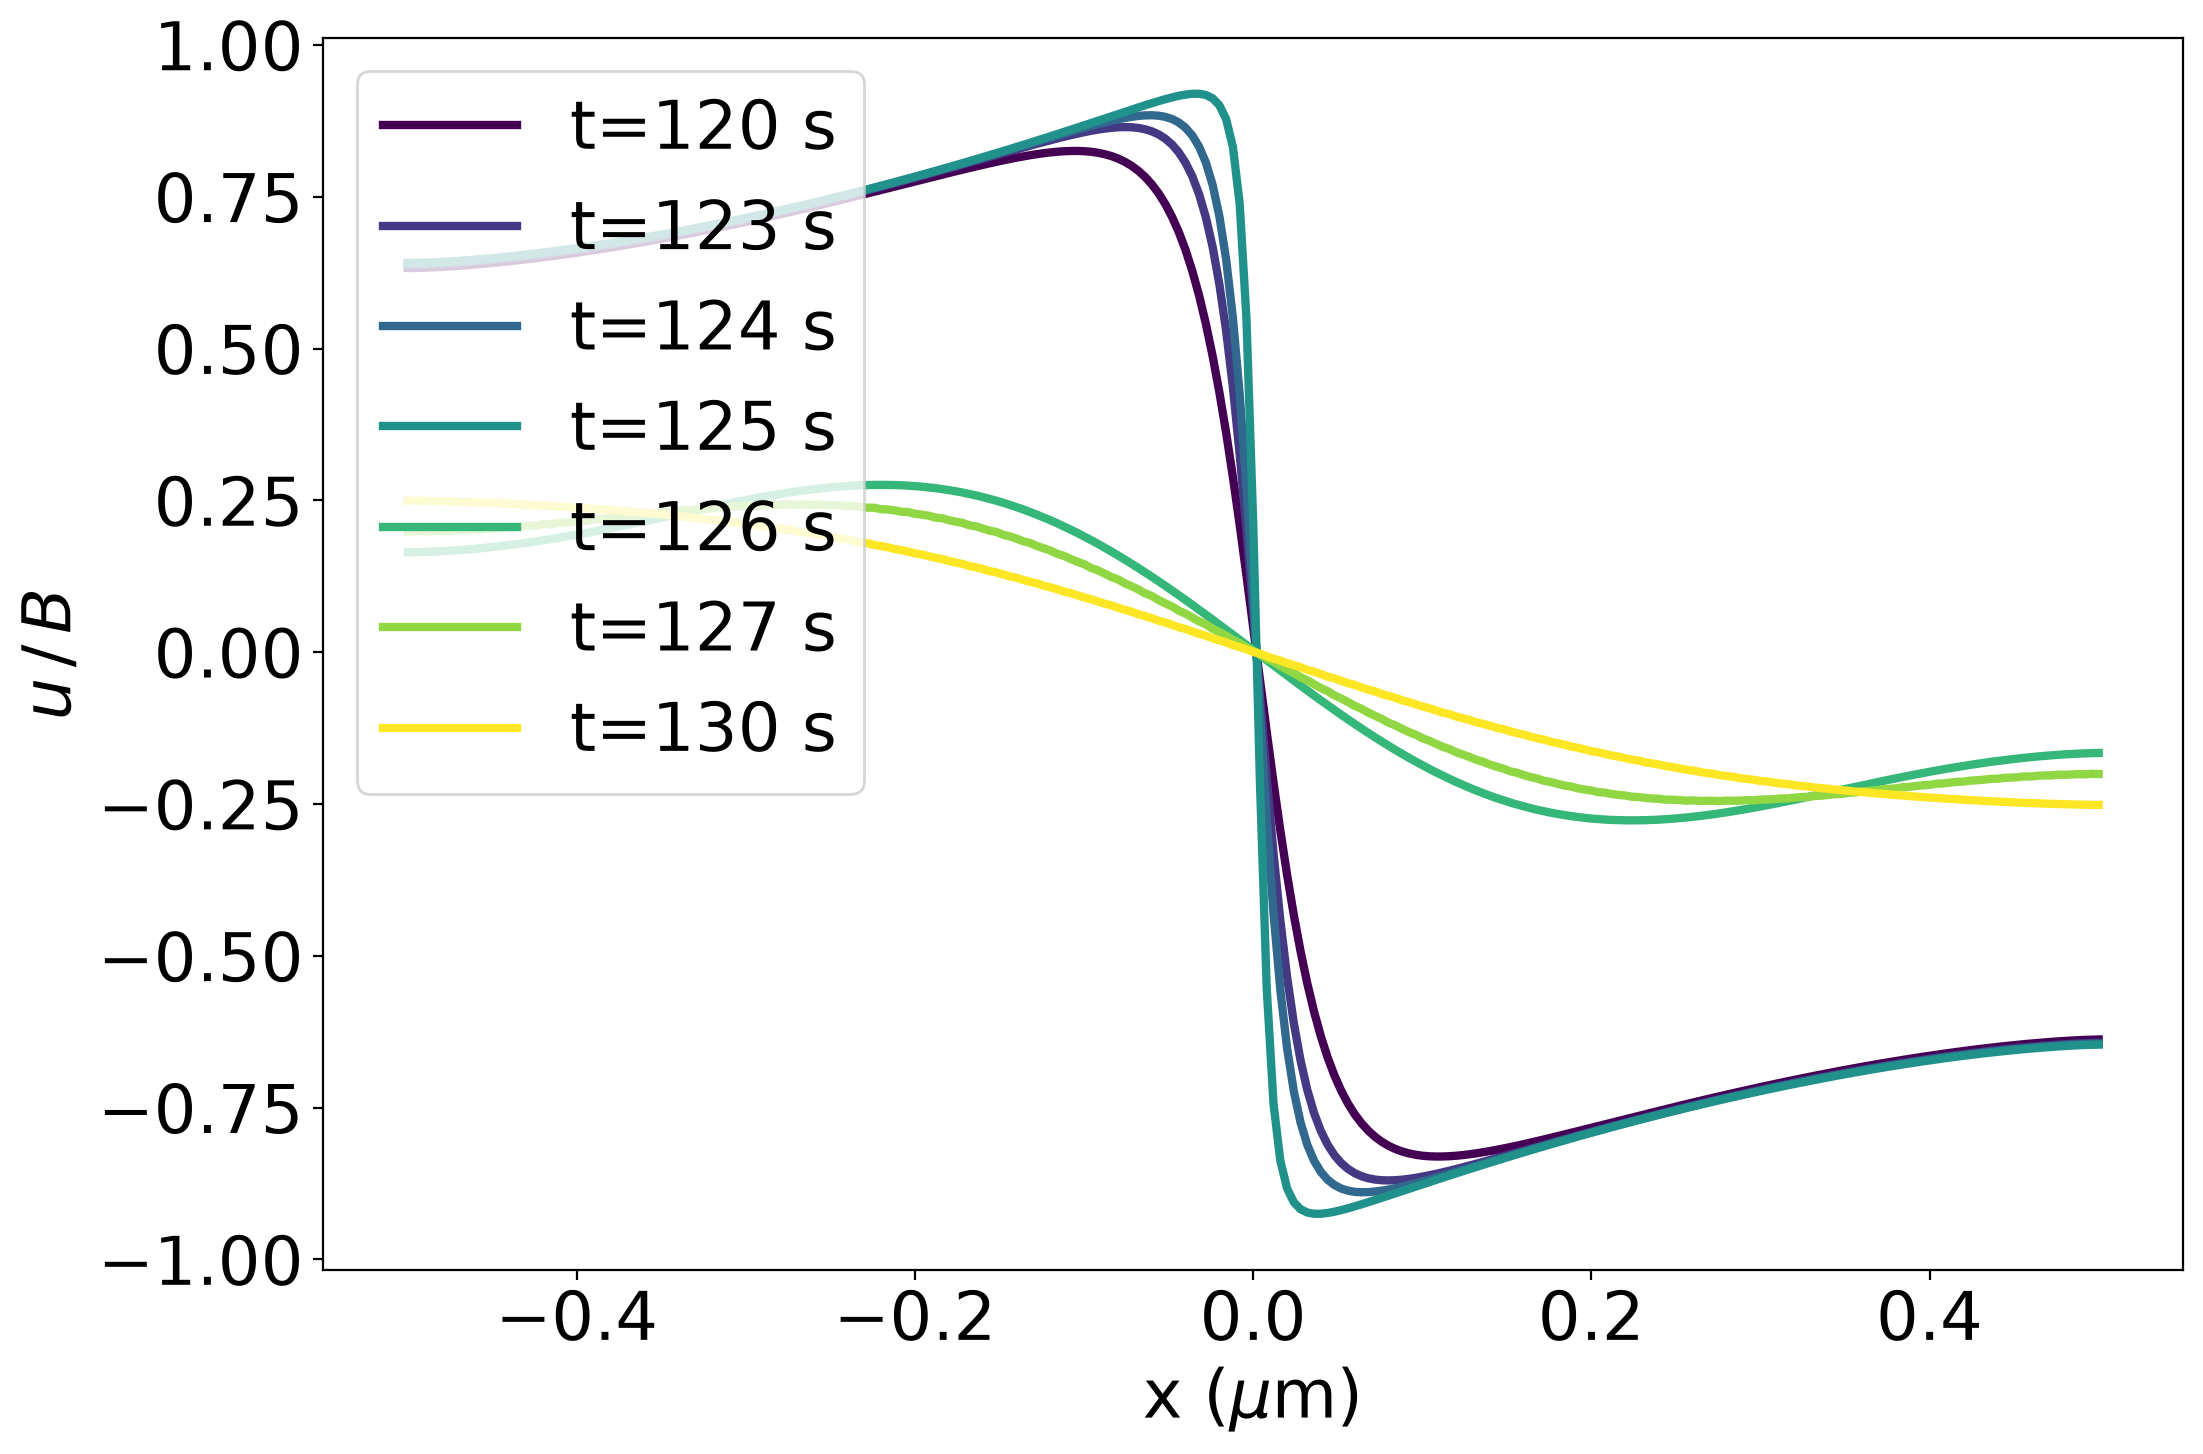

In [5]:
gbdd.plot_field("bfield", times=[120, 123, 124, 125, 126, 127, 130],
                lw=3,
                file="pu1_relax_bfield_after.pdf")
gbdd.plot_field("displacement", times=[120, 123, 124, 125, 126, 127, 130],
                lw=3,
                file="pu1_relax_disp_after.pdf")

In [ ]:
gbT5 = dd.GB_dislocations(from_file="../data/pu1_T5000_H050_L10.h5")
fig, ax1 = plt.subplots(figsize=(12, 8), dpi=200)

# plot total B on the left axis
ax1.set_xlabel(r't (10$^3$ s)')
ax1.set_ylabel(r'$\Sigma b_i/B$', color="b")
ax1.plot(gbT5.sim_time[:]*1.e-9, gbT5.glob_data['n_gbdis_eff'][:], 
         'b-', lw=3)
ax1.tick_params(axis="y", labelcolor="b")

# Create a second axes sharing the same x-axis
ax2 = ax1.twinx()

# Second plot on the right axis
ax2.set_ylabel("y", color="r")
ax2.plot(gbT5.sim_time[:]*1.e-9, gbT5.pu_dis['position'][:], 
         'r-', lw=3)
ax2.tick_params(axis="y", labelcolor="r")

# Adjust layout to prevent label clipping
fig.tight_layout()
#plt.savefig("pu1-relax-totalB_y.pdf", dpi=300)
plt.show()

In [ ]:
gbT5.plot_field("bfield", times=[150, 155, 158, 159, 160],
                lw=3,
                #file="pu1_relax_bfield_T5000.pdf"
               )
gbT5.plot_field("displacement", times=[150, 155, 158, 159, 160],
                lw=3,
                #file="pu1_relax_disp_T5000.pdf"
               )